# Rice Disease Detector — Results for Study

Visualisation of the **held-out test-split** performance of the two classifiers:

- **Health model** — healthy vs. diseased
- **Disease model** — bacterial blight / blast / brown spot

All figures are generated directly from `ml/saved_models/*.json`, so this
notebook stays in sync with the latest training run. Figures are also saved as
PNGs (300 dpi) into `ml/saved_models/figures/` for pasting into the paper.

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ---- resolve project root and active model JSON (same paths as the Django app) ----
HERE = Path.cwd()
ROOT = HERE if (HERE / "ml" / "model_paths.py").exists() else HERE.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from ml.model_paths import (
    MODEL_DIR,
    active_model_label,
    get_model_tag,
    report_path,
    validation_summary_path,
)

SAVED = MODEL_DIR
FIG_DIR = SAVED / "figures"
FIG_DIR.mkdir(exist_ok=True)

with open(report_path(), "r", encoding="utf-8") as f:
    report = json.load(f)
with open(validation_summary_path(), "r", encoding="utf-8") as f:
    val = json.load(f)

# consistent, colour-blind-friendly palette
C_HEALTH  = "#2a9d8f"   # teal
C_DISEASE = "#e76f51"   # terracotta
DISEASE_PALETTE = ["#e76f51", "#f4a261", "#e9c46a", "#8ab17d", "#264653"]

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.axisbelow": True,
})
print("Active model:", active_model_label())
print("Reading from:", SAVED)
print("Report:", report_path().name)
print("Validation:", validation_summary_path().name)
print("Dataset images:", report["total_images"])
print("Disease classes (test eval):", val["disease"]["classes"])

def score_ylim(*value_lists, pad=0.04):
    # Start below the lowest bar so no scores are clipped off the chart.
    vals = [v for group in value_lists for v in group]
    return max(0.0, min(vals) - pad), 1.02

Active model: tag=default
Reading from: C:\Users\cisnl\Desktop\test_agri\rice_disease_project\ml\saved_models
Report: training_report.json
Validation: validation_summary.json
Dataset images: 12147
Disease classes (test eval): ['bacterial blight', 'blast', 'brown spot', 'physiological stress']


## 1. Headline metrics — Health vs. Disease model

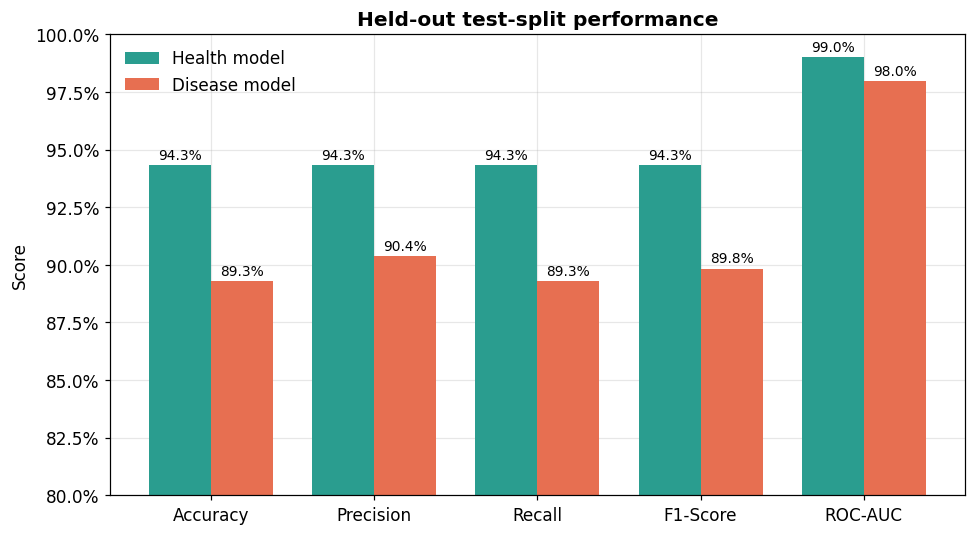

In [2]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
health_vals = [
    val["health"]["accuracy"],
    val["health"]["precision_weighted"],
    val["health"]["recall_weighted"],
    val["health"]["f1_weighted"],
    val["health"]["roc_auc_weighted"],
]
disease_vals = [
    val["disease"]["accuracy"],
    val["disease"]["precision_weighted"],
    val["disease"]["recall_weighted"],
    val["disease"]["f1_weighted"],
    val["disease"]["roc_auc_weighted"],
]

x = np.arange(len(metrics))
w = 0.38
fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - w/2, health_vals,  w, label="Health model",  color=C_HEALTH)
b2 = ax.bar(x + w/2, disease_vals, w, label="Disease model", color=C_DISEASE)

for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h*100:.1f}%", (bar.get_x() + bar.get_width()/2, h),
                    ha="center", va="bottom", fontsize=9,
                    xytext=(0, 2), textcoords="offset points")

ax.set_ylim(0.80, 1.0)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.set_xticks(x, metrics)
ax.set_ylabel("Score")
ax.set_title("Held-out test-split performance", fontweight="bold")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_headline_metrics.png", dpi=300, bbox_inches="tight")
plt.show()

## 2. Test accuracy at a glance

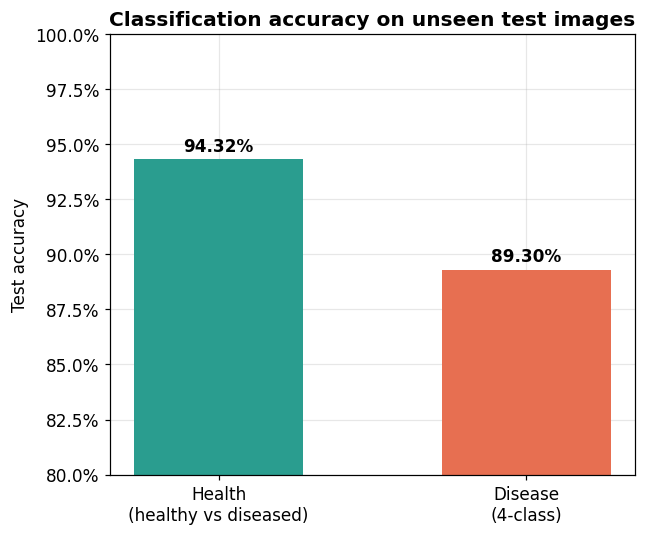

In [3]:
n_disease_classes = len(val["disease"]["classes"])
labels = [
    "Health\n(healthy vs diseased)",
    f"Disease\n({n_disease_classes}-class)",
]
accs = [val["health"]["accuracy"], val["disease"]["accuracy"]]
colors = [C_HEALTH, C_DISEASE]

fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(labels, accs, color=colors, width=0.55)
for bar, a in zip(bars, accs):
    ax.annotate(f"{a*100:.2f}%", (bar.get_x() + bar.get_width()/2, a),
                ha="center", va="bottom", fontweight="bold",
                xytext=(0, 3), textcoords="offset points")
ax.set_ylim(0.80, 1.0)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.set_ylabel("Test accuracy")
ax.set_title("Classification accuracy on unseen test images", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_test_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Cross-validation vs. train / validation / test

The first bar is **cross-validation** score during hyper-parameter tuning
(see `cv_scoring` in the training report — usually macro-F1, not accuracy).
Train, validation, and test bars are **accuracy** on each split.

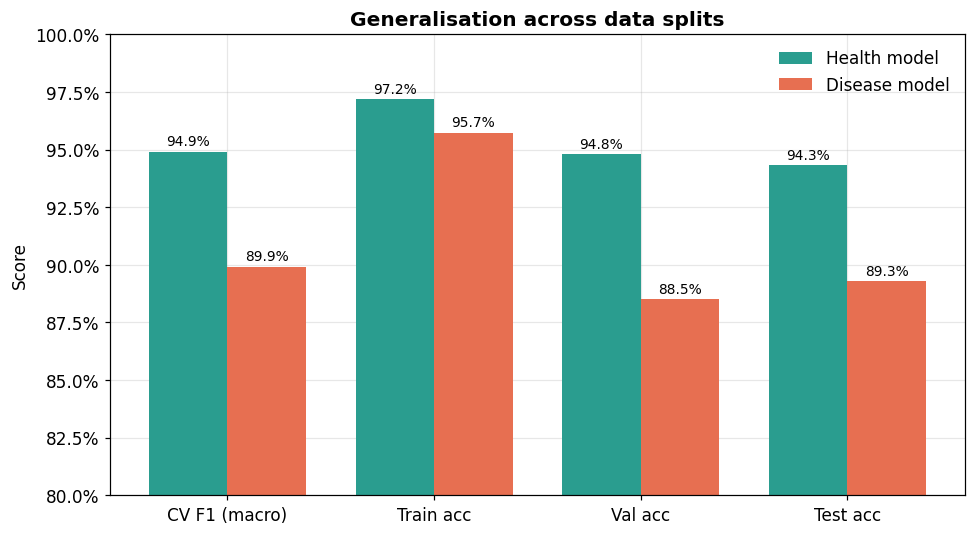

In [4]:
cv_scoring = report.get("cv_scoring", report["health_model"].get("cv_scoring", "f1_macro"))
cv_label = "CV F1 (macro)" if "f1" in cv_scoring else f"CV {cv_scoring}"
splits = [cv_label, "Train acc", "Val acc", "Test acc"]
health_split = [
    report["health_model"]["cv_score"],
    report["health_model"]["train_accuracy"],
    report["health_model"]["val_accuracy"],
    report["health_model"]["test_accuracy"],
]
disease_split = [
    report["disease_model"]["cv_score"],
    report["disease_model"]["train_accuracy"],
    report["disease_model"]["val_accuracy"],
    report["disease_model"]["test_accuracy"],
]

x = np.arange(len(splits))
w = 0.38
fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - w/2, health_split,  w, label="Health model",  color=C_HEALTH)
b2 = ax.bar(x + w/2, disease_split, w, label="Disease model", color=C_DISEASE)
for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h*100:.1f}%", (bar.get_x() + bar.get_width()/2, h),
                    ha="center", va="bottom", fontsize=9,
                    xytext=(0, 2), textcoords="offset points")
ax.set_ylim(0.80, 1.0)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
ax.set_xticks(x, splits)
ax.set_ylabel("Score")
ax.set_title("Generalisation across data splits", fontweight="bold")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_split_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Feature-block importance

Which visual feature families the Random Forest relied on most for each model.

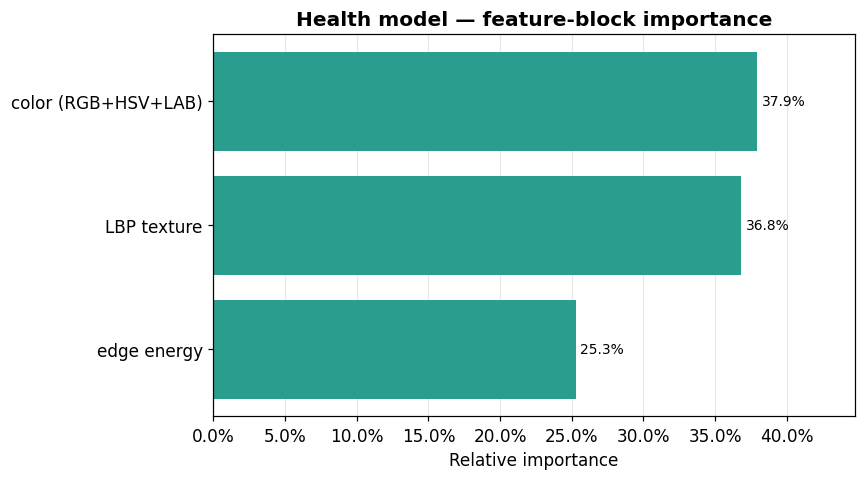

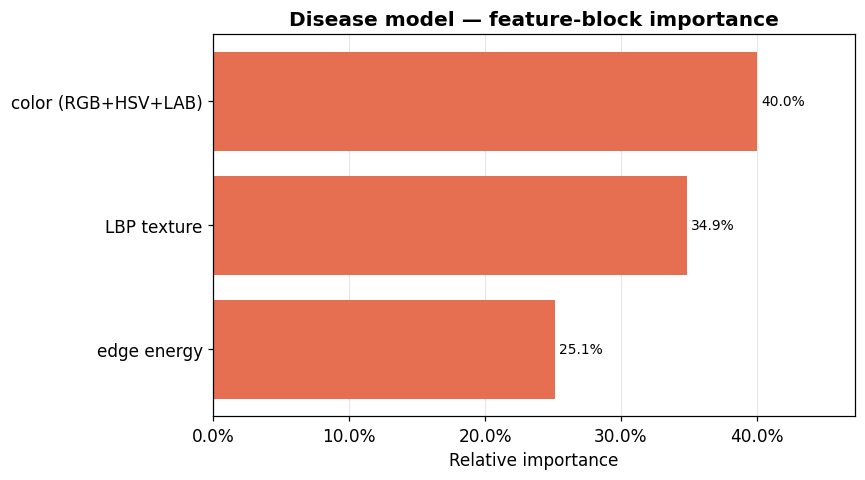

In [5]:
def plot_importance(block_imp, title, color, fname):
    items = [(k, v) for k, v in block_imp.items() if v > 0]
    items.sort(key=lambda kv: kv[1])
    names = [k for k, _ in items]
    vals = [v for _, v in items]
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.barh(names, vals, color=color)
    for bar, v in zip(bars, vals):
        ax.annotate(f"{v*100:.1f}%", (v, bar.get_y() + bar.get_height()/2),
                    va="center", ha="left", fontsize=9,
                    xytext=(3, 0), textcoords="offset points")
    ax.set_xlim(0, max(vals) * 1.18)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
    ax.set_xlabel("Relative importance")
    ax.set_title(title, fontweight="bold")
    ax.grid(axis="y", visible=False)
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=300, bbox_inches="tight")
    plt.show()

plot_importance(report["health_model"]["rf_feature_block_importance"],
                "Health model — feature-block importance", C_HEALTH,
                "04a_health_feature_importance.png")
plot_importance(report["disease_model"]["rf_feature_block_importance"],
                "Disease model — feature-block importance", C_DISEASE,
                "04b_disease_feature_importance.png")

## 5. Dataset composition

Unique images in the dataset and how many **original** image paths were assigned
to each classifier's train / test split. Disease train/test counts are **diseased
leaves only** (a subset of the health dataset, not additive with health counts).

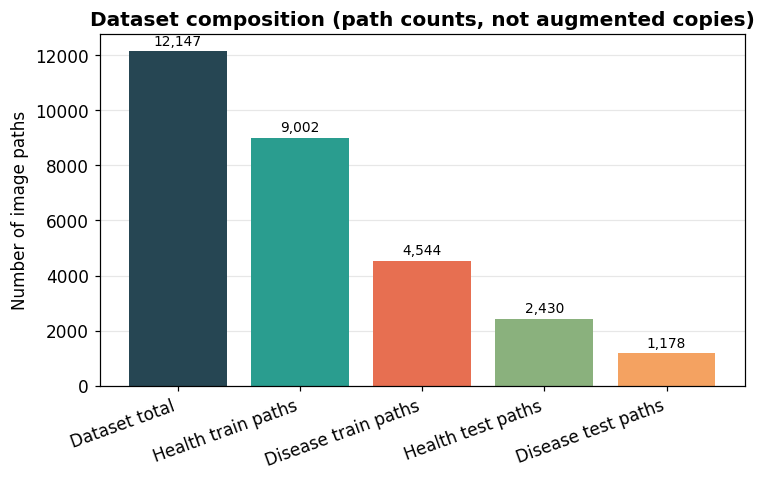

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
cats = [
    "Dataset total",
    "Health train paths",
    "Disease train paths",
    "Health test paths",
    "Disease test paths",
]
vals = [
    report["total_images"],
    report["train_health_samples"],
    report["train_disease_samples"],
    val["health"]["n_test_samples"],
    val["disease"]["n_test_samples"],
]
colors = ["#264653", C_HEALTH, C_DISEASE, "#8ab17d", "#f4a261"]
bars = ax.bar(cats, vals, color=colors)
for bar, v in zip(bars, vals):
    ax.annotate(f"{v:,}", (bar.get_x() + bar.get_width()/2, v),
                ha="center", va="bottom", fontsize=9,
                xytext=(0, 2), textcoords="offset points")
ax.set_ylabel("Number of image paths")
ax.set_title("Dataset composition (path counts, not augmented copies)", fontweight="bold")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_dataset_composition.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. ROC curves

One-vs-rest ROC curve for each class, drawn from the held-out test
predictions (`roc_curve` points stored in `validation_summary.json`). The
weighted area under the curve (AUC) is shown in each panel title; the dashed
diagonal is the no-skill baseline.

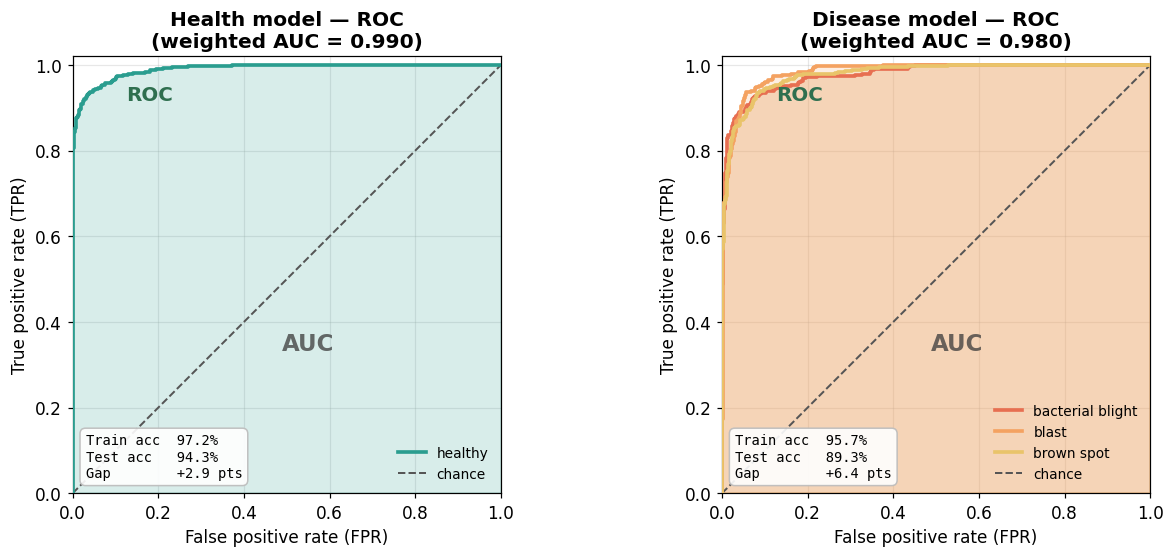

In [8]:
def _valid_roc_curves(curves: dict) -> dict:
    # Drop classes with no test positives (invalid / NaN ROC points).
    valid = {}
    for cls, cur in curves.items():
        tpr = np.asarray(cur.get("tpr", []), dtype=float)
        fpr = np.asarray(cur.get("fpr", []), dtype=float)
        if len(tpr) == 0 or np.isnan(tpr).any() or np.isnan(fpr).any():
            continue
        valid[cls] = cur
    return valid


def plot_roc(ax, model_key, report_key, title, palette):
    m = val[model_key]
    curves = m.get("roc_curve")
    if not curves:
        ax.text(0.5, 0.5, "roc_curve not in JSON\\n(re-run ml/evaluate_models.py)",
                ha="center", va="center", transform=ax.transAxes)
        ax.set_axis_off()
        return
    curves = _valid_roc_curves(curves)
    if not curves:
        ax.text(0.5, 0.5, "No valid ROC curves\\n(all classes absent from test split)",
                ha="center", va="center", transform=ax.transAxes)
        ax.set_axis_off()
        return
    curve_items = list(curves.items())
    colors = [palette[i % len(palette)] for i in range(len(curve_items))]
    for (cls, cur), col in zip(curve_items, colors):
        ax.fill_between(cur["fpr"], cur["tpr"], color=col, alpha=0.18, zorder=1)
        ax.plot(cur["fpr"], cur["tpr"], color=col, lw=2.4, label=cls, zorder=3)
    ax.plot([0, 1], [0, 1], ls="--", lw=1.3, color="#555",
            label="chance", zorder=2)

    ax.annotate("ROC", xy=(0.18, 0.93), fontsize=13, fontweight="bold",
                color="#2f6f4f", ha="center", va="center")
    ax.annotate("AUC", xy=(0.55, 0.35), fontsize=15, fontweight="bold",
                color="#3a3a3a", ha="center", va="center", alpha=0.75)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_aspect("equal")
    ax.set_xlabel("False positive rate (FPR)")
    ax.set_ylabel("True positive rate (TPR)")
    ax.set_title(f"{title}\n(weighted AUC = {m['roc_auc_weighted']:.3f})",
                 fontweight="bold")
    ax.legend(frameon=False, loc="lower right", fontsize=9)

    r = report[report_key]
    tr, te = r["train_accuracy"], r["test_accuracy"]
    gap = tr - te
    txt = (f"Train acc  {tr*100:.1f}%\n"
           f"Test acc   {te*100:.1f}%\n"
           f"Gap        {gap*100:+.1f} pts")
    ax.text(0.03, 0.03, txt, transform=ax.transAxes, ha="left", va="bottom",
            fontsize=9, family="monospace",
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#bbb", alpha=0.9))

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
plot_roc(axes[0], "health", "health_model", "Health model — ROC",
         [C_HEALTH, "#8ab17d"])
plot_roc(axes[1], "disease", "disease_model", "Disease model — ROC",
         DISEASE_PALETTE)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_roc_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. Summary table

The exact numbers behind the figures, ready to drop into the study.

In [9]:
rows = [
    ("Accuracy",  val["health"]["accuracy"],            val["disease"]["accuracy"]),
    ("Precision", val["health"]["precision_weighted"],  val["disease"]["precision_weighted"]),
    ("Recall",    val["health"]["recall_weighted"],     val["disease"]["recall_weighted"]),
    ("F1-Score",  val["health"]["f1_weighted"],         val["disease"]["f1_weighted"]),
    ("ROC-AUC",   val["health"]["roc_auc_weighted"],    val["disease"]["roc_auc_weighted"]),
]
print(f"{'Metric':<12}{'Health':>10}{'Disease':>10}")
print("-" * 32)
for name, h, d in rows:
    print(f"{name:<12}{h:>10.4f}{d:>10.4f}")
print("-" * 32)
print(f"{'Test size':<12}{val['health']['n_test_samples']:>10}{val['disease']['n_test_samples']:>10}")
print(f"\nActive model: {active_model_label()}")
print(f"Figures saved to: {FIG_DIR}")

Metric          Health   Disease
--------------------------------
Accuracy        0.9432    0.8930
Precision       0.9432    0.9039
Recall          0.9432    0.8930
F1-Score        0.9432    0.8983
ROC-AUC         0.9902    0.9798
--------------------------------
Test size         2430      1178

Active model: tag=default
Figures saved to: C:\Users\cisnl\Desktop\test_agri\rice_disease_project\ml\saved_models\figures
